MCS 320 Midterm Two, Friday 13 November 2026

Submit to gradescope before, or at the latest at 1:50pm.

# Question 1

Define a function ``P`` which takes on input 
a list ``X`` of any number of variables $x_1$, $x_2$, $\ldots$, $x_n$, 
and an index ``i``. 

``P(X, i)`` returns the polynomial
$$
         p_i(x) = x_1^3 - \prod_{j=1}^i x_j + 4.
$$

Demonstrate that your function works for $n = 8$, and for all $i$ from 1 to $n$.

## answer to question 1

In [1]:
n = 8

In [2]:
X = [var('x' + str(k)) for k in range(1, n+1)]
X

[x1, x2, x3, x4, x5, x6, x7, x8]

In [3]:
P = lambda X, i: X[0]^3 + prod(X[j-1] for j in range(1, i+1)) + 4

In [4]:
for i in range(1, n+1):
    print(P(X, i))

x1^3 + x1 + 4
x1^3 + x1*x2 + 4
x1^3 + x1*x2*x3 + 4
x1*x2*x3*x4 + x1^3 + 4
x1*x2*x3*x4*x5 + x1^3 + 4
x1*x2*x3*x4*x5*x6 + x1^3 + 4
x1*x2*x3*x4*x5*x6*x7 + x1^3 + 4
x1*x2*x3*x4*x5*x6*x7*x8 + x1^3 + 4


# Question 2

Consider the recurrence
$$
         S_n(x) = (x+1) S_{n-1}(x) + (n-x) S_{n-2}(x), 
         \quad S_0(x) = 1, \quad S_1(x) = x.
$$

Define a function ``S`` which returns $S_n(x)$, using a dictionary for memoization.

Make sure your function can compute $S_{100}(x)$.

## answer to question 2

In [5]:
reset()

In [6]:
def S(n, x, D={}):
    if (n, x) in D:
        return D[(n, x)]
    else:
        if n == 0:
            result = 1
        elif n == 1:
            result = x
        else:
            result = expand((x + 1)*S(n - 1, x) + (n - x)*S(n-2, x))
            D[(n, x)] = result
        return result

In [7]:
S(100, x)

x^100 + 5049*x^98 + 4949*x^97 + 12248578*x^96 + 23678960*x^95 + 19032190655*x^94 + 54373158229*x^93 + 21304634805984*x^92 + 79843226316327*x^91 + 18321976230227215*x^90 + 84290817757639947*x^89 + 12606809788313901941*x^88 + 68191751757326046718*x^87 + 7136505459716170435721*x^86 + 44004770389955445927825*x^85 + 3391759693254792387195841*x^84 + 23279912785070217935081670*x^83 + 1374325741737376681618014039*x^82 + 10298580165312822567951730075*x^81 + 480464971624930829149682373294*x^80 + 3866821538576465101657595965046*x^79 + 146299997911489197421351289977594*x^78 + 1246557783134328919335142247344730*x^77 + 39095036119257407416662159443650649*x^76 + 348176089209170847519679098135315280*x^75 + 9224306993233494993170815154760876105*x^74 + 84873693748920425563958706568541283149*x^73 + 1931074738202080515352687607499138600014*x^72 + 18162965037386217618413571073762599579008*x^71 + 360083531323513799980679568679408447781920*x^70 + 3428540475604455027964279384038257633041160*x^69 + 59988303127

# Question 3

Let $f = \exp(-x^2) \sin(2 \pi x)$.

1. Compute the first ten terms of the Taylor series of $f$.

2. Construct a rational approximation $r$ (over the reals), where the numerator has degree 6 and denominator has degree 3.

3. Make a plot of the $r$ and $f$ (in red) for $x \in [-1,1]$.

   Compute the error (as a real number) at $x=0.1$.

## answer to question 3

In [8]:
reset()

In [9]:
f = exp(-x^2)*sin(2*pi*x)
show(f)

e^(-x^2)*sin(2*pi*x)

In [10]:
tf = taylor(f, x, 0, 10)
show(tf)

1/11340*(945*pi + 16*pi^9 + 288*pi^7 + 1512*pi^5 + 2520*pi^3)*x^9 - 1/315*(105*pi + 8*pi^7 + 84*pi^5 + 210*pi^3)*x^7 + 1/15*(15*pi + 4*pi^5 + 20*pi^3)*x^5 - 2/3*(3*pi + 2*pi^3)*x^3 + 2*pi*x

In [11]:
pf = tf.power_series(RR)
show(pf)

0.000000000000000 + 6.28318530717959*x + 0.000000000000000*x^2 - 47.6248875475793*x^3 + 0.000000000000000*x^4 + 126.088544170065*x^5 + 0.000000000000000*x^6 - 180.029157700533*x^7 + 0.000000000000000*x^8 + 166.719261430529*x^9 + O(x^10)

In [12]:
r = pf.pade(6,3)
show(r)

(40.6848128031393*x^6 - 27.0722600764298*x^4 + 4.40060764740594*x^2)/(x^3 + 0.700378459692651*x)

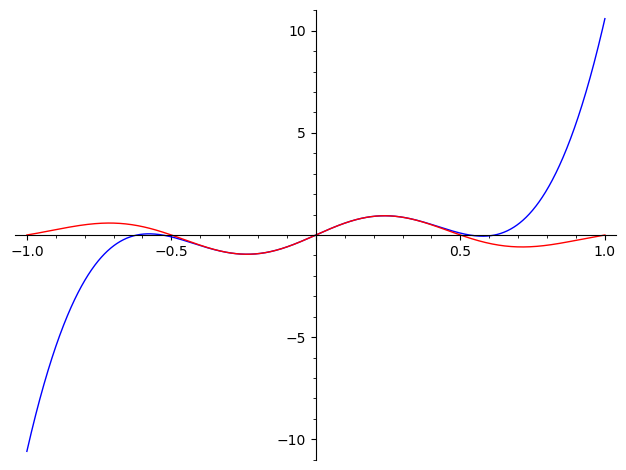

In [13]:
pltr = plot(r, (x, -1, 1))
pltf = plot(f, (x, -1, 1), color='red')
show(pltr+pltf)

In [14]:
err = abs(RR(f(x=0.1)) - r(x=0.1))
show(err)

8.78110408830679e-8

# Question 4

When formulating a polynomial system we cast the expressions into a polynomial ring.  
 
How do we cast the polynomials in the ring back into SageMath expressions?
 
Give a good example we covered in the course.

## answer to question 4

In [15]:
reset()

To convert an object in a polynomial ring into a SageMath expression, we can cast the object into the symbolic ring via SR() or substitute the variables of the object by new symbols.

In [16]:
R.<x,y> = PolynomialRing(QQ)
p = R.random_element()
show(p)

1/2*x^2 + x - 12*y - 2

In [17]:
type(p)

<class 'sage.rings.polynomial.multi_polynomial_libsingular.MPolynomial_libsingular'>

In [18]:
q = SR(p)
show(q)

1/2*x^2 + x - 12*y - 2

In [19]:
type(q)

<class 'sage.symbolic.expression.Expression'>

In the examples of the course, we applied the SR() to solve equations defined by polynomials in a Groebner basis.

# Question 5

Consider the curve defined by 
$p(x, y) = (x^2 - 4 y + y^2)^2 - 16 (x^2 + y^2) = 0$.

1. Plot the curve for a good range of $x$ and $y$.

2. Transform the curve into polar coordinates and plot.

3. Describe the differences between the two plots.

## answer to question 5

In [20]:
reset()

In [21]:
x, y = var('x, y')

In [22]:
p = (x^2 - 4*y + y^2)^2 - 16*(x^2 + y^2)
show(p)

(x^2 + y^2 - 4*y)^2 - 16*x^2 - 16*y^2

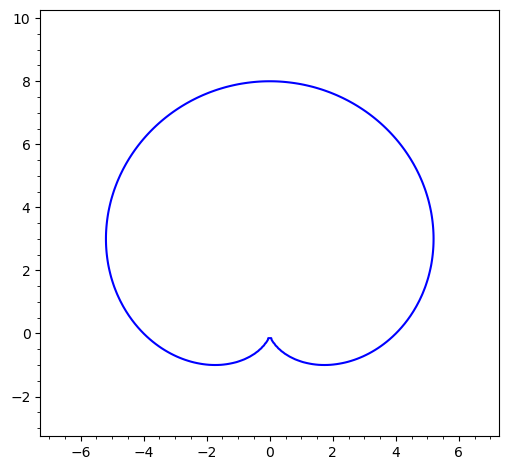

In [23]:
implicit_plot(p, (x, -7, 7), (y, -3 ,10))

In [24]:
r, t = var('r, t')
rp = p(x = r*cos(t), y=r*sin(t))
show(rp)

-16*r^2*cos(t)^2 - 16*r^2*sin(t)^2 + (r^2*cos(t)^2 + r^2*sin(t)^2 - 4*r*sin(t))^2

In [25]:
rt = solve(rp, r)
rt

[r == -4*(sqrt(cos(t)^2 + sin(t)^2) - sin(t))/(cos(t)^2 + sin(t)^2), r == 4*(sqrt(cos(t)^2 + sin(t)^2) + sin(t))/(cos(t)^2 + sin(t)^2), r == 0]

In [26]:
rt0 = rt[0].rhs()
show(rt0)

-4*(sqrt(cos(t)^2 + sin(t)^2) - sin(t))/(cos(t)^2 + sin(t)^2)

In [27]:
st0 = rt0.trig_simplify()
show(st0)

4*sin(t) - 4

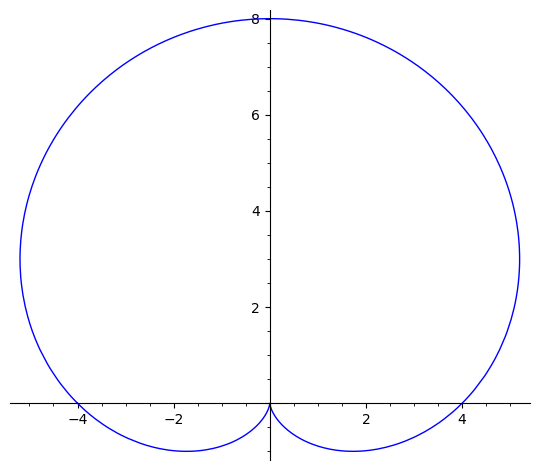

In [28]:
polar_plot(st0, (t, 0, 2*pi))

The main difference between the plots in rectangular and polar coordinates is at the origin, where the polar plot is more accurate.  In polar coordinates, the multiplicities are resolved.

# Question 6

Consider $f(x,y) = x - y^3 + 3 y = 0$ and $g(x, y) = y - x^3 + 3 x = 0$.

1. How many real solutions does the system defined by $f$ and $g$ have?

2. Plot the curves defined by $f$ and $g$, using red and green respectively.

   Mark the intersection points of the curves by blue disks.

## answer to question 6

In [29]:
reset()

In [30]:
x, y = var('x, y')

In [31]:
f = x - y^3 + 3*y
show(f)

-y^3 + x + 3*y

In [32]:
g = y - x^3 + 3*x
show(g)

-x^3 + 3*x + y

In [33]:
sols = solve([f, g], (x, y), solution_dict=True)
sols

[{x: 1/2*sqrt(5) + 1/2, y: -1/2*sqrt(5) + 1/2},
 {x: -1/2*sqrt(5) + 1/2, y: 1/2*sqrt(5) + 1/2},
 {x: sqrt(2), y: -sqrt(2)},
 {x: -sqrt(2), y: sqrt(2)},
 {x: 1/2*sqrt(5) - 1/2, y: -1/2*sqrt(5) - 1/2},
 {x: -1/2*sqrt(5) - 1/2, y: 1/2*sqrt(5) - 1/2},
 {x: 2, y: 2},
 {x: -2, y: -2},
 {x: 0, y: 0}]

In [34]:
len(sols)

9

We observe that all 9 solutions are real.

In [35]:
pts = point([(s[x].n(), s[y].n()) for s in sols], color="blue", size=45)

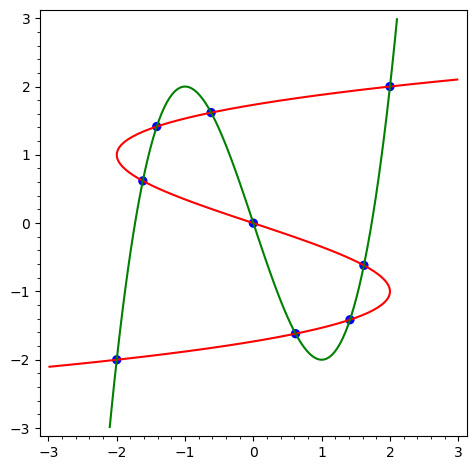

In [36]:
pf = implicit_plot(f, (x, -3, 3), (y, -3, 3), color='red')
pg = implicit_plot(g, (x, -3, 3), (y, -3, 3), color='green')
(pf+pg+pts).show()

# Question 7

Consider $y$ as a function of $x$ in the initial value problem
$$
         \exp(x) \sin(y) \frac{d~\!y}{d~\!x} - \exp(x) \cos(y) - 2 x,
         \quad y(0) = 1.
$$
Solve this problem and plot its solution for $x \in [0, 4 \pi]$.

## answer to question 7

In [37]:
reset()

In [38]:
y = function('y')(x)

In [39]:
ode = diff(y,x)*exp(x)*sin(y) - exp(x)*cos(y) - 2*x
show(ode)

e^x*sin(y(x))*diff(y(x), x) - cos(y(x))*e^x - 2*x

In [40]:
sol = desolve(ode,ivar=x,dvar=y,ics=[0, 1])
show(sol)

-x^2 - cos(y(x))*e^x == -cos(1)

In [41]:
ysol = solve(sol, y)
show(ysol)

[y(x) == pi - arccos(x^2*e^(-x) - cos(1)*e^(-x))]

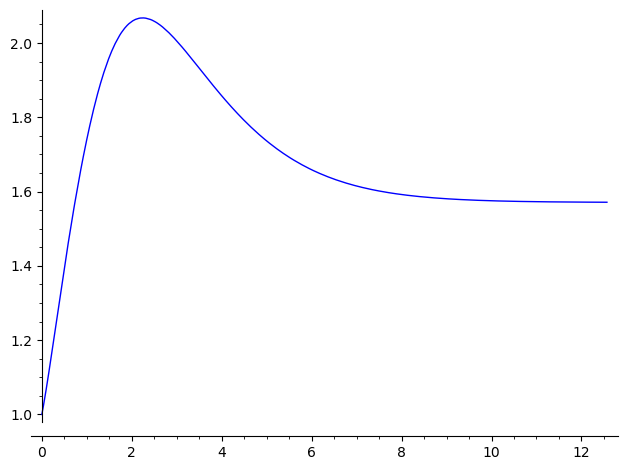

In [42]:
psol = ysol[0].rhs()
plot(psol, (x, 0, 4*pi))